[INFO] BaseAviary.__init__() loaded parameters from the drone's .urdf:
[INFO] m 0.027000, L 0.039700,
[INFO] ixx 0.000014, iyy 0.000014, izz 0.000022,
[INFO] kf 3.160000e-10, km 7.940000e-12,
[INFO] t2w 2.250000, max_speed_kmh 30.000000,
[INFO] gnd_eff_coeff 11.368590, prop_radius 0.023135,
[INFO] drag_xy_coeff 0.000001, drag_z_coeff 0.000001,
[INFO] dw_coeff_1 2267.180000, dw_coeff_2 0.160000, dw_coeff_3 -0.110000
viewMatrix (0.642787516117096, -0.4393851161003113, 0.6275069713592529, 0.0, 0.766044557094574, 0.36868777871131897, -0.5265407562255859, 0.0, -0.0, 0.8191521167755127, 0.5735764503479004, 0.0, 2.384185791015625e-07, 2.384185791015625e-07, -5.000000476837158, 1.0)
projectionMatrix (0.7499999403953552, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, -1.0000200271606445, -1.0, 0.0, 0.0, -0.02000020071864128, 0.0)


C:\Users\night\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\spaces\box.py:231: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
C:\Users\night\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\spaces\box.py:297: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


=== LINEARIZED QUATERNION CONTROLLER STATE-SPACE MATRICES ===
u_hover: [14468.4 14468.4 14468.4 14468.4]
A_c: (12, 12), B_c: (12, 15), C_c: (4, 12), D_c: (4, 15)


error: Not connected to physics server.

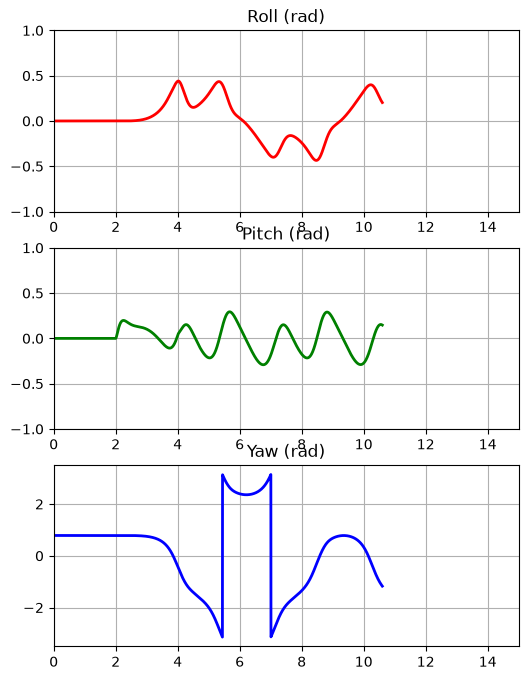

In [1]:
import time
import math
import numpy as np
import pybullet as p
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R
from gym_pybullet_drones.envs.CtrlAviary import CtrlAviary
from gym_pybullet_drones.control.DSLPIDControl import DSLPIDControl


class PaperQuaternionController(DSLPIDControl):
    """
    Cascaded Quaternion Attitude Control System 
    """
    def __init__(self, drone_model):
        super().__init__(drone_model=drone_model)
        self.KP_QUAT = 12.0
        self.MAX_RATE_SP = 10.0
        self.KP_RATE = np.array([4500.0, 4500.0, 3500.0])
        self.KI_RATE = np.array([250.0,  250.0,  150.0])
        self.KD_RATE = np.array([15.0,   15.0,   0.0])
        self.reset_all_states()

    def reset_all_states(self):
        self.reset()
        self.integral_pos_e = np.zeros(3)
        self.rate_integral = np.zeros(3)
        self.prev_omega_meas = np.zeros(3)
        self.d_omega_filt = np.zeros(3)
        self.first_step = True

    @staticmethod
    def quat_multiply(q1, q2):
        w1, x1, y1, z1 = q1
        w2, x2, y2, z2 = q2
        return np.array([
            w1*w2 - x1*x2 - y1*y2 - z1*z2,
            w1*x2 + x1*w2 + y1*z2 - z1*y2,
            w1*y2 - x1*z2 + y1*w2 + z1*x2,
            w1*z2 + x1*y2 - y1*x2 + z1*w2
        ])

    @staticmethod
    def quat_conjugate(q):
        return np.array([q[0], -q[1], -q[2], -q[3]])

    def computeControlFromState(self, control_timestep, state, target_pos, target_vel, target_acc, target_yaw):
        cur_pos = state[0:3]
        cur_quat_xyzw = state[3:7]
        cur_vel = state[10:13]
        cur_ang_vel_world = state[13:16]

        # 1. GUIDANCE SYSTEM (GS)
        pos_e = target_pos - cur_pos
        vel_e = target_vel - cur_vel

        self.integral_pos_e = self.integral_pos_e + pos_e * control_timestep
        self.integral_pos_e = np.clip(self.integral_pos_e, -2.0, 2.0)
        self.integral_pos_e[2] = np.clip(self.integral_pos_e[2], -0.15, 0.15)

        mass = self.GRAVITY / 9.8
        target_force = (
            mass * (
                self.P_COEFF_FOR * pos_e
                + self.I_COEFF_FOR * self.integral_pos_e
                + self.D_COEFF_FOR * vel_e
                + target_acc
            )
            + np.array([0.0, 0.0, self.GRAVITY])
        )

        R_meas = R.from_quat(cur_quat_xyzw).as_matrix()
        scalar_thrust = max(0.0, np.dot(target_force, R_meas[:, 2]))
        thrust = (math.sqrt(scalar_thrust / (4.0 * self.KF)) - self.PWM2RPM_CONST) / self.PWM2RPM_SCALE

        z_body_des = target_force / np.linalg.norm(target_force)
        x_c_des = np.array([math.cos(target_yaw), math.sin(target_yaw), 0.0])
        y_body_des = np.cross(z_body_des, x_c_des)
        y_body_des /= np.linalg.norm(y_body_des)
        x_body_des = np.cross(y_body_des, z_body_des)

        R_sp = np.column_stack((x_body_des, y_body_des, z_body_des))
        q_sp_xyzw = R.from_matrix(R_sp).as_quat()

        q_sp = np.array([q_sp_xyzw[3], q_sp_xyzw[0], q_sp_xyzw[1], q_sp_xyzw[2]])
        q_meas = np.array([cur_quat_xyzw[3], cur_quat_xyzw[0], cur_quat_xyzw[1], cur_quat_xyzw[2]])
        q_sp /= np.linalg.norm(q_sp)
        q_meas /= np.linalg.norm(q_meas)

        # 2. Q_P ATTITUDE CONTROLLER
        q_err = self.quat_multiply(self.quat_conjugate(q_meas), q_sp)
        q_err_short = -q_err if q_err[0] < 0.0 else q_err
        omega_sp = np.clip(2.0 * self.KP_QUAT * q_err_short[1:4], -self.MAX_RATE_SP, self.MAX_RATE_SP)

        # 3. INNER ANGULAR RATE PI-D CONTROLLERS
        omega_meas = R_meas.T @ cur_ang_vel_world
        omega_err = omega_sp - omega_meas

        self.rate_integral += omega_err * control_timestep
        self.rate_integral = np.clip(self.rate_integral, -0.5, 0.5)

        if self.first_step:
            self.d_omega_filt = np.zeros(3)
            self.first_step = False
        else:
            raw_d_omega = (omega_meas - self.prev_omega_meas) / control_timestep
            self.d_omega_filt = 0.2 * raw_d_omega + 0.8 * self.d_omega_filt
        self.prev_omega_meas = omega_meas.copy()

        target_torques = (
            self.KP_RATE * omega_err
            + self.KI_RATE * self.rate_integral
            - self.KD_RATE * self.d_omega_filt
        )
        target_torques = np.clip(target_torques, -3200.0, 3200.0)

        pwm = thrust + np.dot(self.MIXER_MATRIX, target_torques)
        pwm = np.clip(pwm, self.MIN_PWM, self.MAX_PWM)
        rpm = self.PWM2RPM_SCALE * pwm + self.PWM2RPM_CONST

        return rpm, pos_e, q_err_short


# =====================================================================
# NUMERICAL STATE-SPACE LINEARIZATION OF PAPER QUATERNION CONTROLLER
# =====================================================================
def linearize_quaternion_controller(ctrl_obj, dt):
    """
    Linearizes PaperQuaternionController around the local yaw-aligned hover equilibrium:
      Controller Internal State x_c (12x1): [integral_pos_e(3), rate_integral(3), prev_omega(3), d_omega_filt(3)]
      Controller Input Vector e_in (15x1):  [e_pos_loc(3), e_vel_loc(3), acc_ff_loc(3), e_rpy(3), e_omega_body(3)]
      Output Vector u (4x1):                4 Motor RPM commands
    Returns: u_hover (4,), A_c (12,12), B_c (12,15), C_c (4,12), D_c (4,15)
    """
    pos_eq = np.array([0.0, 0.0, 1.5])

    def eval_step(x_c, e_in):
        # Set internal controller states
        ctrl_obj.integral_pos_e = x_c[0:3].copy()
        ctrl_obj.rate_integral = x_c[3:6].copy()
        ctrl_obj.prev_omega_meas = x_c[6:9].copy()
        ctrl_obj.d_omega_filt = x_c[9:12].copy()
        ctrl_obj.first_step = False

        # Map input perturbations around hover
        t_pos = pos_eq + e_in[0:3]
        t_vel = e_in[3:6].copy()
        t_acc = e_in[6:9].copy()
        cur_rpy = np.array([-e_in[9], -e_in[10], 0.0])
        t_yaw = e_in[11]
        cur_quat = R.from_euler('xyz', cur_rpy).as_quat()
        cur_ang_vel = -e_in[12:15]

        state = np.zeros(20)
        state[0:3] = pos_eq
        state[3:7] = cur_quat
        state[7:10] = cur_rpy
        state[13:16] = cur_ang_vel

        rpm, _, _ = ctrl_obj.computeControlFromState(dt, state, t_pos, t_vel, t_acc, t_yaw)
        x_c_next = np.concatenate([
            ctrl_obj.integral_pos_e,
            ctrl_obj.rate_integral,
            ctrl_obj.prev_omega_meas,
            ctrl_obj.d_omega_filt
        ])
        return x_c_next, rpm

    x0 = np.zeros(12)
    e0 = np.zeros(15)
    _, u_hover = eval_step(x0, e0)

    eps = 1e-5
    A_c = np.zeros((12, 12))
    B_c = np.zeros((12, 15))
    C_c = np.zeros((4, 12))
    D_c = np.zeros((4, 15))

    for i in range(12):
        dx = np.zeros(12)
        dx[i] = eps
        x_p, u_p = eval_step(x0 + dx, e0)
        x_m, u_m = eval_step(x0 - dx, e0)
        A_c[:, i] = (x_p - x_m) / (2.0 * eps)
        C_c[:, i] = (u_p - u_m) / (2.0 * eps)

    for j in range(15):
        de = np.zeros(15)
        de[j] = eps
        x_p, u_p = eval_step(x0, e0 + de)
        x_m, u_m = eval_step(x0, e0 - de)
        B_c[:, j] = (x_p - x_m) / (2.0 * eps)
        D_c[:, j] = (u_p - u_m) / (2.0 * eps)

    ctrl_obj.reset_all_states()
    return u_hover, A_c, B_c, C_c, D_c


# =====================================================================
# MAIN 3D SIMULATION WITH LINEARIZED STATE-SPACE MODEL
# =====================================================================
INIT_XYZ = np.array([[0.0, 0.0, 1.5]])
INIT_RPY = np.array([[0.0, 0.0, math.pi/4]])

env = CtrlAviary(gui=True, record=False, initial_xyzs=INIT_XYZ, initial_rpys=INIT_RPY)
ctrl = PaperQuaternionController(drone_model=env.DRONE_MODEL)

ctrl.P_COEFF_FOR = np.array([8.0, 8.0, 10.0])
ctrl.I_COEFF_FOR = np.array([1.5, 1.5, 2.0])
ctrl.D_COEFF_FOR = np.array([5.5, 5.5, 6.0])

# Extract Linear State-Space Matrices (A_c, B_c, C_c, D_c)
u_hover, A_c, B_c, C_c, D_c = linearize_quaternion_controller(ctrl, env.CTRL_TIMESTEP)
print("=== LINEARIZED QUATERNION CONTROLLER STATE-SPACE MATRICES ===")
print(f"u_hover: {np.round(u_hover, 1)}")
print(f"A_c: {A_c.shape}, B_c: {B_c.shape}, C_c: {C_c.shape}, D_c: {D_c.shape}")

obs, info = env.reset()
client = env.CLIENT
SPEED = 1.0

# Pre-draw Red Reference Figure-8 Path
theta_path = np.linspace(0, 2*math.pi, 200)
path_x = 2.0 * np.sin(theta_path)
path_y = 2.0 * np.sin(theta_path) * np.cos(theta_path)
path_z = np.full_like(theta_path, 1.5)

for i in range(len(theta_path) - 1):
    p.addUserDebugLine(
        [path_x[i], path_y[i], path_z[i]],
        [path_x[i+1], path_y[i+1], path_z[i+1]],
        [1, 0, 0], 2.0, 0, physicsClientId=client
    )

# Live Telemetry Dashboard
plt.ion()
fig, (ax_roll, ax_pitch, ax_yaw) = plt.subplots(3, 1, figsize=(6, 8))
fig.canvas.manager.set_window_title('Live Flight Telemetry (Linearized Quaternion Model)')

for ax, title in zip([ax_roll, ax_pitch, ax_yaw], ['Roll (rad)', 'Pitch (rad)', 'Yaw (rad)']):
    ax.set_title(title)
    ax.set_xlim(0, 15)
    ax.set_ylim(-1.0, 1.0)
    ax.grid(True)
ax_yaw.set_ylim(-3.5, 3.5)

line_roll, = ax_roll.plot([], [], 'r-', lw=2)
line_pitch, = ax_pitch.plot([], [], 'g-', lw=2)
line_yaw, = ax_yaw.plot([], [], 'b-', lw=2)

time_data, roll_data, pitch_data, yaw_data = [], [], [], []
prev_actual_pos = obs[0][0:3]

# Initialize Linear Controller State Vector x_c (12x1)
x_c = np.zeros(12)

for i in range(3600):
    if not p.isConnected(physicsClientId=client):
        break

    t = i * env.CTRL_TIMESTEP
    current_state = obs[0]
    current_pos = current_state[0:3]
    current_quat = current_state[3:7]
    current_rpy = current_state[7:10]
    current_vel = current_state[10:13]
    current_ang_vel = current_state[13:16]

    # Kinematic Profiling
    if t < 2.0:
        theta, theta_dot, theta_ddot = 0.0, 0.0, 0.0
    elif t < 4.0:
        theta_ddot = SPEED / 2.0
        theta_dot = theta_ddot * (t - 2.0)
        theta = 0.5 * theta_ddot * (t - 2.0)**2
    else:
        theta_ddot = 0.0
        theta_dot = SPEED
        theta = SPEED + SPEED * (t - 4.0)

    target_pos = np.array([2.0 * math.sin(theta), 2.0 * math.sin(theta) * math.cos(theta), 1.5])
    vx = 2.0 * math.cos(theta) * theta_dot
    vy = 2.0 * math.cos(2.0 * theta) * theta_dot
    target_vel = np.array([vx, vy, 0.0])

    ax_ff = -2.0 * math.sin(theta) * (theta_dot**2) + 2.0 * math.cos(theta) * theta_ddot
    ay_ff = -4.0 * math.sin(2.0 * theta) * (theta_dot**2) + 2.0 * math.cos(2.0 * theta) * theta_ddot
    target_acc = np.array([ax_ff, ay_ff, 0.0])
    target_yaw = math.pi / 4 if (vx == 0 and vy == 0) else math.atan2(vy, vx)

    time_data.append(t)
    roll_data.append(current_rpy[0])
    pitch_data.append(current_rpy[1])
    yaw_data.append(current_rpy[2])

    p.addUserDebugLine(prev_actual_pos, current_pos, [0, 0, 1], 2.0, 0, physicsClientId=client)
    prev_actual_pos = current_pos

    if i % 48 == 0:
        line_roll.set_data(time_data, roll_data)
        line_pitch.set_data(time_data, pitch_data)
        line_yaw.set_data(time_data, yaw_data)
        fig.canvas.draw_idle()
        fig.canvas.flush_events()

    # =====================================================================
    # PURE LINEARIZED STATE-SPACE EXECUTION (NO NONLINEAR CONTROLLER CALL)
    # =====================================================================
    yaw = current_rpy[2]
    cos_y, sin_y = math.cos(yaw), math.sin(yaw)
    R_z_T = np.array([
        [ cos_y, sin_y, 0.0],
        [-sin_y, cos_y, 0.0],
        [   0.0,   0.0, 1.0]
    ])

    e_pos_loc = R_z_T @ (target_pos - current_pos)
    e_vel_loc = R_z_T @ (target_vel - current_vel)
    acc_ff_loc = R_z_T @ target_acc

    e_yaw = (target_yaw - yaw + math.pi) % (2.0 * math.pi) - math.pi
    e_rpy = np.array([-current_rpy[0], -current_rpy[1], e_yaw])

    # Linearized local angular velocity error (-omega_body)
    e_omega_body = -(R_z_T @ current_ang_vel)

    # Assemble 15x1 Input Vector
    e_vec = np.concatenate([e_pos_loc, e_vel_loc, acc_ff_loc, e_rpy, e_omega_body])

    # State-Space Output & State Update: u = u_hover + C_c*x_c + D_c*e_vec
    action = u_hover + (C_c @ x_c) + (D_c @ e_vec)
    action = np.clip(action, 0.0, env.MAX_RPM)

    x_c = (A_c @ x_c) + (B_c @ e_vec)
    # Anti-windup bounds matching controller limits
    x_c[0:2] = np.clip(x_c[0:2], -2.0, 2.0)
    x_c[2] = np.clip(x_c[2], -0.15, 0.15)
    x_c[3:6] = np.clip(x_c[3:6], -0.5, 0.5)

    obs, reward, terminated, truncated, info = env.step(np.array([action]))
    time.sleep(env.CTRL_TIMESTEP)

plt.ioff()
plt.show()
if p.isConnected(physicsClientId=client):
    env.close()

[INFO] BaseAviary.__init__() loaded parameters from the drone's .urdf:
[INFO] m 0.027000, L 0.039700,
[INFO] ixx 0.000014, iyy 0.000014, izz 0.000022,
[INFO] kf 3.160000e-10, km 7.940000e-12,
[INFO] t2w 2.250000, max_speed_kmh 30.000000,
[INFO] gnd_eff_coeff 11.368590, prop_radius 0.023135,
[INFO] drag_xy_coeff 0.000001, drag_z_coeff 0.000001,
[INFO] dw_coeff_1 2267.180000, dw_coeff_2 0.160000, dw_coeff_3 -0.110000


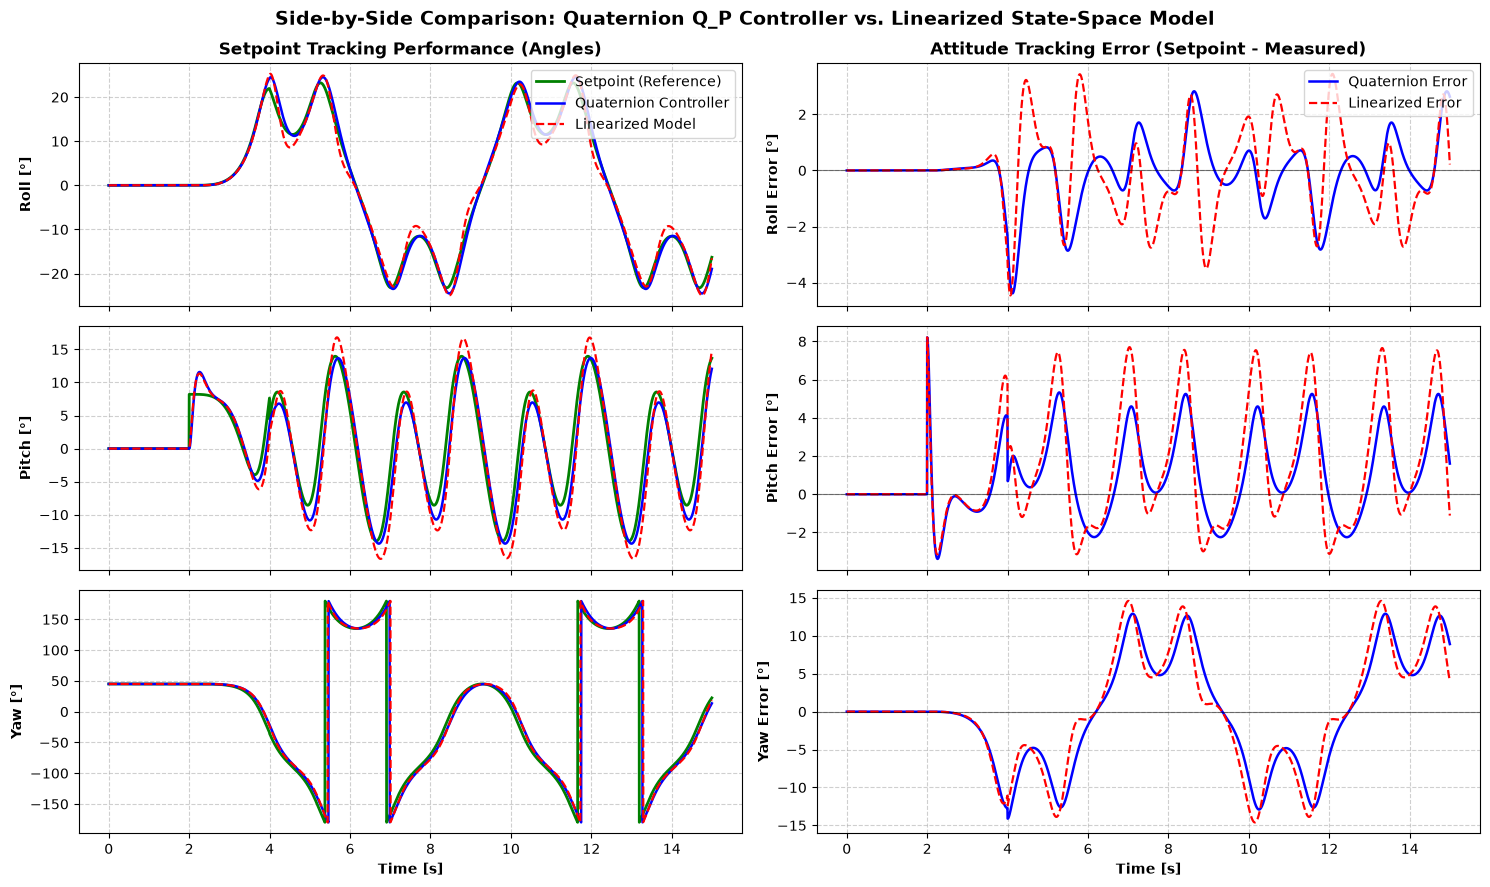

=== ATTITUDE TRACKING RMSE SUMMARY (DEGREES) ===
Roll  RMSE -> Quaternion Q_P: 1.111° | Linearized Model: 1.482°
Pitch RMSE -> Quaternion Q_P: 2.322° | Linearized Model: 3.276°
Yaw   RMSE -> Quaternion Q_P: 7.035° | Linearized Model: 7.341°


In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R
from gym_pybullet_drones.envs.CtrlAviary import CtrlAviary

# =====================================================================
# HEADLESS EVALUATION FUNCTION (NO GUI WINDOW, INSTANT EXECUTION)
# =====================================================================
def evaluate_controllers_headless(steps=3600, speed=1.0):
    INIT_XYZ = np.array([[0.0, 0.0, 1.5]])
    INIT_RPY = np.array([[0.0, 0.0, math.pi/4]])

    # Initialize headless physics environment for data generation
    env = CtrlAviary(gui=False, record=False, initial_xyzs=INIT_XYZ, initial_rpys=INIT_RPY)
    dt = env.CTRL_TIMESTEP

    ctrl = PaperQuaternionController(drone_model=env.DRONE_MODEL)
    ctrl.P_COEFF_FOR = np.array([8.0, 8.0, 10.0])
    ctrl.I_COEFF_FOR = np.array([1.5, 1.5, 2.0])
    ctrl.D_COEFF_FOR = np.array([5.5, 5.5, 6.0])

    u_hover, A_c, B_c, C_c, D_c = linearize_quaternion_controller(ctrl, dt)
    mass = ctrl.GRAVITY / 9.8

    results = {}

    for mode in ['nonlinear', 'linear']:
        obs, _ = env.reset()
        ctrl.reset_all_states()
        x_c = np.zeros(12)

        t_log = []
        rpy_ref_log = []
        rpy_meas_log = []
        rpy_err_log = []

        for i in range(steps):
            t = i * dt
            state = obs[0]
            cur_pos = state[0:3]
            cur_rpy = state[7:10]
            cur_vel = state[10:13]
            cur_ang_vel = state[13:16]

            # Predefined Figure-8 Trajectory
            if t < 2.0:
                theta, theta_dot, theta_ddot = 0.0, 0.0, 0.0
            elif t < 4.0:
                theta_ddot = speed / 2.0
                theta_dot = theta_ddot * (t - 2.0)
                theta = 0.5 * theta_ddot * (t - 2.0)**2
            else:
                theta_ddot = 0.0
                theta_dot = speed
                theta = speed + speed * (t - 4.0)

            target_pos = np.array([2.0 * math.sin(theta), 2.0 * math.sin(theta) * math.cos(theta), 1.5])
            vx = 2.0 * math.cos(theta) * theta_dot
            vy = 2.0 * math.cos(2.0 * theta) * theta_dot
            target_vel = np.array([vx, vy, 0.0])

            ax_ff = -2.0 * math.sin(theta) * (theta_dot**2) + 2.0 * math.cos(theta) * theta_ddot
            ay_ff = -4.0 * math.sin(2.0 * theta) * (theta_dot**2) + 2.0 * math.cos(2.0 * theta) * theta_ddot
            target_acc = np.array([ax_ff, ay_ff, 0.0])
            target_yaw = math.pi / 4 if (vx == 0 and vy == 0) else math.atan2(vy, vx)

            # Compute exact Reference Attitude (Roll_ref, Pitch_ref, Yaw_ref) from trajectory dynamics
            f_ref = mass * target_acc + np.array([0.0, 0.0, ctrl.GRAVITY])
            z_ref = f_ref / np.linalg.norm(f_ref)
            xc_ref = np.array([math.cos(target_yaw), math.sin(target_yaw), 0.0])
            y_ref = np.cross(z_ref, xc_ref)
            y_ref /= np.linalg.norm(y_ref)
            x_ref = np.cross(y_ref, z_ref)
            R_ref = np.column_stack((x_ref, y_ref, z_ref))
            rpy_ref = R.from_matrix(R_ref).as_euler('xyz', degrees=True)

            cur_rpy_deg = np.degrees(cur_rpy)
            err_roll = rpy_ref[0] - cur_rpy_deg[0]
            err_pitch = rpy_ref[1] - cur_rpy_deg[1]
            err_yaw = (rpy_ref[2] - cur_rpy_deg[2] + 180.0) % 360.0 - 180.0

            t_log.append(t)
            rpy_ref_log.append(rpy_ref)
            rpy_meas_log.append(cur_rpy_deg)
            rpy_err_log.append([err_roll, err_pitch, err_yaw])

            if mode == 'nonlinear':
                action, _, _ = ctrl.computeControlFromState(
                    dt, state, target_pos, target_vel, target_acc, target_yaw
                )
            else:
                yaw = cur_rpy[2]
                cos_y, sin_y = math.cos(yaw), math.sin(yaw)
                R_z_T = np.array([
                    [ cos_y, sin_y, 0.0],
                    [-sin_y, cos_y, 0.0],
                    [   0.0,   0.0, 1.0]
                ])
                e_pos_loc = R_z_T @ (target_pos - cur_pos)
                e_vel_loc = R_z_T @ (target_vel - cur_vel)
                acc_ff_loc = R_z_T @ target_acc
                e_yaw_rad = (target_yaw - yaw + math.pi) % (2.0 * math.pi) - math.pi
                e_rpy_rad = np.array([-cur_rpy[0], -cur_rpy[1], e_yaw_rad])
                e_omega_body = -(R_z_T @ cur_ang_vel)

                e_vec = np.concatenate([e_pos_loc, e_vel_loc, acc_ff_loc, e_rpy_rad, e_omega_body])
                action = np.clip(u_hover + (C_c @ x_c) + (D_c @ e_vec), 0.0, env.MAX_RPM)
                x_c = (A_c @ x_c) + (B_c @ e_vec)
                x_c[0:2] = np.clip(x_c[0:2], -2.0, 2.0)
                x_c[2] = np.clip(x_c[2], -0.15, 0.15)
                x_c[3:6] = np.clip(x_c[3:6], -0.5, 0.5)

            obs, _, _, _, _ = env.step(np.array([action]))

        results[mode] = {
            't': np.array(t_log),
            'ref': np.array(rpy_ref_log),
            'meas': np.array(rpy_meas_log),
            'err': np.array(rpy_err_log)
        }

    env.close()
    return results

# Run headless comparison and plot side-by-side
res = evaluate_controllers_headless(steps=3600, speed=1.0)
t = res['nonlinear']['t']
ref = res['nonlinear']['ref']
q_meas, q_err = res['nonlinear']['meas'], res['nonlinear']['err']
l_meas, l_err = res['linear']['meas'], res['linear']['err']

fig, axes = plt.subplots(3, 2, figsize=(15, 9), sharex=True)
fig.suptitle('Side-by-Side Comparison: Quaternion Q_P Controller vs. Linearized State-Space Model', fontsize=14, fontweight='bold')

labels = ['Roll', 'Pitch', 'Yaw']
for idx, name in enumerate(labels):
    # Left Column: Angle Setpoint Tracking
    ax_ang = axes[idx, 0]
    ax_ang.plot(t, ref[:, idx], 'g-', lw=2.0, label='Setpoint (Reference)')
    ax_ang.plot(t, q_meas[:, idx], 'b-', lw=1.8, label='Quaternion Controller')
    ax_ang.plot(t, l_meas[:, idx], 'r--', lw=1.6, label='Linearized Model')
    ax_ang.set_ylabel(f'{name} [°]', fontweight='bold')
    ax_ang.grid(True, linestyle='--', alpha=0.6)
    if idx == 0:
        ax_ang.set_title('Setpoint Tracking Performance (Angles)', fontweight='bold')
        ax_ang.legend(loc='upper right')

    # Right Column: Attitude Tracking Error
    ax_err = axes[idx, 1]
    ax_err.plot(t, q_err[:, idx], 'b-', lw=1.8, label='Quaternion Error')
    ax_err.plot(t, l_err[:, idx], 'r--', lw=1.6, label='Linearized Error')
    ax_err.axhline(0, color='k', lw=0.8, alpha=0.5)
    ax_err.set_ylabel(f'{name} Error [°]', fontweight='bold')
    ax_err.grid(True, linestyle='--', alpha=0.6)
    if idx == 0:
        ax_err.set_title('Attitude Tracking Error (Setpoint - Measured)', fontweight='bold')
        ax_err.legend(loc='upper right')

axes[2, 0].set_xlabel('Time [s]', fontweight='bold')
axes[2, 1].set_xlabel('Time [s]', fontweight='bold')
plt.tight_layout()
plt.show()

# Print Quantitative RMSE Table
print("=== ATTITUDE TRACKING RMSE SUMMARY (DEGREES) ===")
for idx, name in enumerate(labels):
    rmse_q = np.sqrt(np.mean(q_err[:, idx]**2))
    rmse_l = np.sqrt(np.mean(l_err[:, idx]**2))
    print(f"{name:5s} RMSE -> Quaternion Q_P: {rmse_q:.3f}° | Linearized Model: {rmse_l:.3f}°")